# Federated Semantic Segmentation: FedAvg · FedProx · FedADMM · FedDyn · SCAFFOLD · FedNova (+ FedBN / SiloBN)

Runs the `fedseg` package on **CamVid** (sequence-disjoint SegNet split, one client per drive sequence) and on
**Oxford-IIIT Pet** (label skew: cat-only and dog-only clients). Results, checkpoints and plots go to Google
Drive; re-running a cell skips finished runs and resumes unfinished ones.

## 1. Setup

In [ ]:
import os, sys, subprocess
!nvidia-smi -L

USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/fedseg_runs'
else:
    OUT_DIR = '/content/runs'
DATA_ROOT = '/content/data'
os.makedirs(OUT_DIR, exist_ok=True)

GPU 0: Tesla T4 (UUID: GPU-e5d31cdf-b8e0-dcaf-9701-3889e91eabe7)
Mounted at /content/drive


In [ ]:
REPO = '/content/Federated-learning'
CODE = f'{REPO}/semantic-segmentation'
if not os.path.isdir(REPO):
    !git clone -q https://github.com/EMES888/Federated-learning.git {REPO}
os.chdir(CODE)
sys.path.insert(0, CODE)

In [ ]:
!pip -q install tabulate
import torch, torchvision
print('torch', torch.__version__, 'torchvision', torchvision.__version__, 'cuda', torch.cuda.is_available())

torch 2.14.1+cu130 torchvision 0.29.1+cu130 cuda True


## 2. Data
CamVid (~180 MB) is fetched with a sparse `git` checkout of the SegNet-Tutorial repository. Oxford-IIIT Pet
(~800 MB) comes from the official VGG mirror. Both are downloaded automatically on first use; this cell just
pre-fetches them and prints the client partitions.

In [ ]:
from fedseg.data import build_bundle
for ds in ['camvid', 'pets']:
    b = build_bundle(ds, DATA_ROOT, download=True)
    print(f'{ds}: train={len(b.train)} val={len(b.val)} test={len(b.test)} classes={b.class_names}')

camvid: train=367 val=101 test=233 classes=['Sky', 'Building', 'Pole', 'Road', 'Sidewalk', 'Tree', 'SignSymbol', 'Fence', 'Car', 'Pedestrian', 'Bicyclist']
downloading https://thor.robots.ox.ac.uk/datasets/pets/images.tar.gz -> /content/data/oxford-iiit-pet/images.tar.gz
extracting /content/data/oxford-iiit-pet/images.tar.gz
downloading https://thor.robots.ox.ac.uk/datasets/pets/annotations.tar.gz -> /content/data/oxford-iiit-pet/annotations.tar.gz
extracting /content/data/oxford-iiit-pet/annotations.tar.gz
pets: train=3311 val=369 test=3669 classes=['background', 'cat', 'dog']


## 3. Experiments
`PRESET = 'quick'`: 20 rounds × 2 local epochs, one seed. Model: DeepLabV3 with an ImageNet-pretrained
MobileNetV3 backbone.

In [ ]:
import experiments as E
PRESET = 'quick'
SEEDS  = (0,)
MODEL  = 'deeplabv3_mbv3'
COMMON = dict(out_dir=OUT_DIR, data_root=DATA_ROOT, num_workers=2)

### 3.1 CamVid: natural non-IID (one client per drive sequence: 0001TP dusk · 0006R0 · 0016E5)
Baselines: centralized (upper bound) and local-only (lower bound). FL methods: FedAvg, FedProx, FedADMM,
FedDyn, SCAFFOLD, FedNova and FedAvgM. Normalisation handling: FedBN and SiloBN.

In [ ]:
E.run_suite(E.camvid_suite(model=MODEL), preset=PRESET, seeds=SEEDS, common=COMMON)

[skip] camvid_deeplabv3_mbv3_centralized_s0 already finished
[skip] camvid_deeplabv3_mbv3_local_natural3_s0 already finished
[skip] camvid_deeplabv3_mbv3_fedavg_natural3_s0 already finished
[skip] camvid_deeplabv3_mbv3_fedprox_natural3_s0 already finished
[skip] camvid_deeplabv3_mbv3_fedadmm_natural3_s0 already finished
[skip] camvid_deeplabv3_mbv3_feddyn_natural3_s0 already finished
[skip] camvid_deeplabv3_mbv3_scaffold_natural3_s0 already finished
[skip] camvid_deeplabv3_mbv3_fednova_natural3_s0 already finished
[skip] camvid_deeplabv3_mbv3_fedavg_natural3_srvmomentum_s0 already finished
[skip] camvid_deeplabv3_mbv3_fedavg_natural3_fedbn_s0 already finished
[skip] camvid_deeplabv3_mbv3_fedavg_natural3_silobn_s0 already finished
[skip] camvid_deeplabv3_mbv3_fedadmm_natural3_silobn_s0 already finished


[]

### 3.2 CamVid: system heterogeneity
6 clients with partial participation (3 of 6 per round) and random local epochs drawn from {1, 2, 3}.

In [ ]:
E.run_suite(E.camvid_system_hetero_suite(model=MODEL), preset=PRESET, seeds=SEEDS, common=COMMON)

[skip] camvid_deeplabv3_mbv3_fedavg_natural6_s0 already finished
[skip] camvid_deeplabv3_mbv3_fedprox_natural6_s0 already finished
[skip] camvid_deeplabv3_mbv3_fedadmm_natural6_s0 already finished
[skip] camvid_deeplabv3_mbv3_fednova_natural6_s0 already finished
[skip] camvid_deeplabv3_mbv3_scaffold_natural6_s0 already finished


[]

### 3.3 Oxford-IIIT Pet: label-skew non-IID
Classes are background, cat and dog. 6 clients, 3 sampled per round. The `natural` split chunks breeds in
order, giving 2 cat-only and 4 dog-only clients (pixel-class JS ≈ 0.10).

In [ ]:
E.run_suite(E.pets_suite(model=MODEL, partition='natural'), preset=PRESET, seeds=SEEDS, common=COMMON)

[skip] pets_deeplabv3_mbv3_centralized_s0 already finished
[skip] pets_deeplabv3_mbv3_fedavg_natural6_s0 already finished
[skip] pets_deeplabv3_mbv3_fedprox_natural6_s0 already finished
[data] pets: train=3311 val=369 test=3669 size=(224, 224) classes=3
[data] natural partition over 6 clients: sizes=[530, 539, 540, 536, 626, 540] JS=0.097
        client 0: {'Abyssinian': 90, 'Bengal': 90, 'Birman': 90, 'Bombay': 86, 'British_Shorthair': 90, 'Egyptian_Mau': 84}
        client 1: {'Maine_Coon': 90, 'Persian': 90, 'Ragdoll': 90, 'Russian_Blue': 90, 'Siamese': 89, 'Sphynx': 90}
        client 2: {'american_bulldog': 90, 'american_pit_bull_terrier': 90, 'basset_hound': 90, 'beagle': 90, 'boxer': 90, 'chihuahua': 90}
        client 3: {'english_cocker_spaniel': 86, 'english_setter': 90, 'german_shorthaired': 90, 'great_pyrenees': 90, 'havanese': 90, 'japanese_chin': 90}
        client 4: {'keeshond': 90, 'leonberger': 90, 'miniature_pinscher': 90, 'newfoundland': 86, 'pomeranian': 90, 'pug':

100%|██████████| 21.1M/21.1M [00:00<00:00, 195MB/s]


[model] deeplabv3_mbv3: 11.02M params, 42.1 MB shared per upload, local keys=0
[resume] continuing from round 15
[pets_deeplabv3_mbv3_fedadmm_natural6_s0] round  16/20 lr=0.0015 train_loss=76.9227 | val loss=nan mIoU=0.2222 acc=0.6665 (38.1s)
[pets_deeplabv3_mbv3_fedadmm_natural6_s0] round  17/20 lr=0.0010 train_loss=55.0740 | val loss=nan mIoU=0.2222 acc=0.6665 (21.0s)
[pets_deeplabv3_mbv3_fedadmm_natural6_s0] round  18/20 lr=0.0006 train_loss=68.5172 | val loss=nan mIoU=0.2222 acc=0.6665 (22.5s)
[error] pets_deeplabv3_mbv3_fedadmm_natural6_s0 failed:
Traceback (most recent call last):
  File "/content/code/fedseg_code/experiments.py", line 90, in run_suite
    results.append(run_experiment(cfg))
                   ~~~~~~~~~~~~~~^^^^^
  File "/content/code/fedseg_code/fedseg/trainer.py", line 463, in run_experiment
    return FederatedTrainer(cfg).run()
           ~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/content/code/fedseg_code/fedseg/trainer.py", line 397, in run
    msgs.append(self.tr

[]

### 3.4 Hyper-parameter sensitivity: FedADMM ρ and FedProx μ

In [ ]:
base = dict(dataset='camvid', model=MODEL, img_size=(240, 320), partition='natural', num_clients=3,
            batch_size=8, class_weights='inv_sqrt')
E.run_suite(E.sweep({**base, 'algorithm': 'fedadmm'}, 'rho', [0.001, 0.01, 0.1, 1.0]), PRESET, SEEDS, COMMON)
E.run_suite(E.sweep({**base, 'algorithm': 'fedprox'}, 'mu',  [0.001, 0.01, 0.1, 1.0]), PRESET, SEEDS, COMMON)

[data] camvid: train=367 val=101 test=233 size=(240, 320) classes=11
[data] natural partition over 3 clients: sizes=[62, 101, 204] JS=0.020
        client 0: {'0001TP': 62}
        client 1: {'0006R0': 101}
        client 2: {'0016E5': 204}
[model] deeplabv3_mbv3: 11.02M params, 42.2 MB shared per upload, local keys=0
[resume] no checkpoint found, starting from scratch
[camvid_fedadmm_rho0.001] round   1/20 lr=0.0100 train_loss=1.3781 | val loss=2.3759 mIoU=0.3004 acc=0.7653 (23.7s)
[camvid_fedadmm_rho0.001] round   2/20 lr=0.0099 train_loss=0.8938 | val loss=1.0055 mIoU=0.4138 acc=0.7766 (15.7s)
[camvid_fedadmm_rho0.001] round   3/20 lr=0.0098 train_loss=0.7775 | val loss=0.7949 mIoU=0.4757 acc=0.8401 (22.6s)
[camvid_fedadmm_rho0.001] round   4/20 lr=0.0095 train_loss=0.7217 | val loss=0.7038 mIoU=0.4807 acc=0.8170 (22.9s)
[camvid_fedadmm_rho0.001] round   5/20 lr=0.0091 train_loss=0.6658 | val loss=0.7853 mIoU=0.4585 acc=0.7920 (15.5s)
[camvid_fedadmm_rho0.001] round   6/20 lr=0.0086

### 3.5 SegNet-Basic from scratch
3 clients, 6 local epochs, 14 rounds, SGD with lr 0.01.

In [ ]:
base = dict(dataset='camvid', model='segnet', img_size=(256, 320), partition='natural', num_clients=3,
            local_epochs=6, rounds=14, batch_size=4, class_weights='median_freq')
E.run_suite([{**base, 'algorithm': 'fedavg'}, {**base, 'algorithm': 'fedprox', 'mu': 0.01},
             {**base, 'algorithm': 'fedadmm', 'rho': 0.01}], 'quick', SEEDS, COMMON)

[data] camvid: train=367 val=101 test=233 size=(256, 320) classes=11
[data] natural partition over 3 clients: sizes=[62, 101, 204] JS=0.020
        client 0: {'0001TP': 62}
        client 1: {'0006R0': 101}
        client 2: {'0016E5': 204}
[model] segnet: 1.42M params, 5.4 MB shared per upload, local keys=0
[resume] no checkpoint found, starting from scratch
[camvid_segnet_fedavg_natural3_s0] round   1/14 lr=0.0100 train_loss=1.7177 | val loss=2.4507 mIoU=0.1199 acc=0.3859 (45.4s)
[camvid_segnet_fedavg_natural3_s0] round   2/14 lr=0.0099 train_loss=1.5053 | val loss=3.1572 mIoU=0.1002 acc=0.4097 (41.5s)
[camvid_segnet_fedavg_natural3_s0] round   3/14 lr=0.0095 train_loss=1.3132 | val loss=2.0205 mIoU=0.2021 acc=0.4878 (42.0s)
[camvid_segnet_fedavg_natural3_s0] round   4/14 lr=0.0089 train_loss=1.1461 | val loss=1.3326 mIoU=0.3355 acc=0.6035 (42.3s)
[camvid_segnet_fedavg_natural3_s0] round   5/14 lr=0.0081 train_loss=1.0454 | val loss=1.0773 mIoU=0.3736 acc=0.6529 (42.6s)
[camvid_segne

## 4. Results

In [ ]:
import pandas as pd
from IPython.display import Image, display, Markdown
from fedseg import viz
runs = viz.load_runs(OUT_DIR)
df = viz.summary_table(runs)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
display(df.drop(columns=['run']).round(4))
if len(set(df.seed)) > 1:
    display(viz.aggregate_seeds(df).round(4))

,dataset,model,algorithm,bn_mode,server_opt,partition,clients,seed,test_mIoU,test_pixel_acc,test_mean_acc,pers_mIoU,best_round,comm_MB,time_min,JS_skew
0,camvid,deeplabv3_mbv3,centralized,avg,sgd,iid,1,0,0.4861,0.8275,0.6588,NaN,16,1686.2321,5.4884,0.0000
19,camvid,deeplabv3_mbv3,fedadmm,avg,sgd,natural,3,0,0.4143,0.7744,0.5702,NaN,20,5058.6964,5.4589,0.0200
10,camvid,deeplabv3_mbv3,fednova,avg,sgd,natural,3,0,0.4074,0.7697,0.5785,NaN,19,5058.6964,5.3849,0.0200
6,camvid,deeplabv3_mbv3,fedavg,silobn,sgd,natural,3,0,0.4065,0.7768,0.5610,0.3807,10,5045.8864,6.8529,0.0200
4,camvid,deeplabv3_mbv3,fedavg,fedbn,sgd,natural,3,0,0.4058,0.7755,0.5591,0.3814,10,5033.0763,6.8666,0.0200
15,camvid,deeplabv3_mbv3,scaffold,avg,sgd,natural,3,0,0.4049,0.7697,0.5715,NaN,19,10117.3929,6.7794,0.0200
21,camvid,deeplabv3_mbv3,fedprox,avg,sgd,natural,3,0,0.4041,0.7731,0.5635,NaN,10,5058.6964,5.3295,0.0200
12,camvid,deeplabv3_mbv3,fedprox,avg,sgd,natural,3,0,0.4040,0.7737,0.5628,NaN,10,5058.6964,4.9175,0.0200
5,camvid,deeplabv3_mbv3,fedavg,avg,sgd,natural,3,0,0.4034,0.7728,0.5626,NaN,10,5058.6964,4.8164,0.0200
22,camvid,deeplabv3_mbv3,fedprox,avg,sgd,natural,3,0,0.4029,0.7725,0.5628,NaN,10,5058.6964,5.4309,0.0200


python3: can't open file '/content/code/compare.py': [Errno 2] No such file or directory


**camvid_mIoU_vs_comm.png**

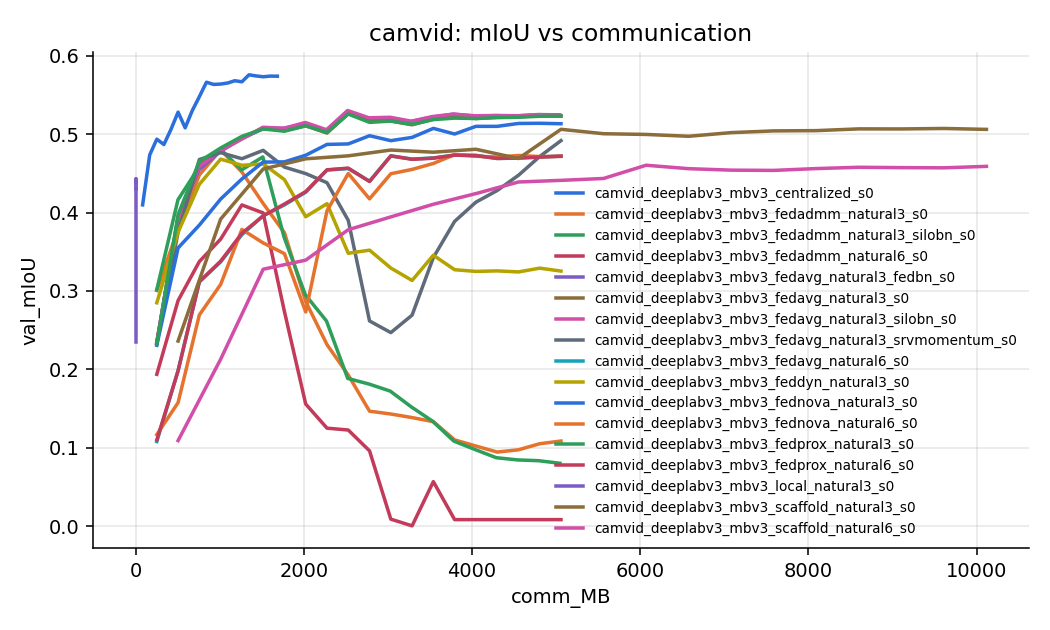

**camvid_train_loss.png**

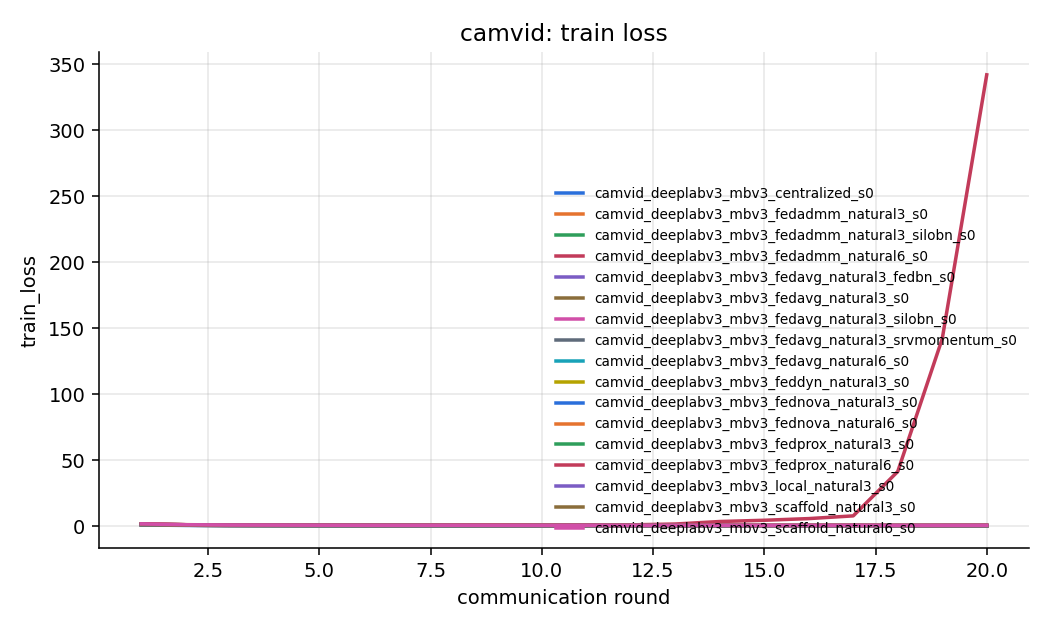

**camvid_val_mIoU.png**

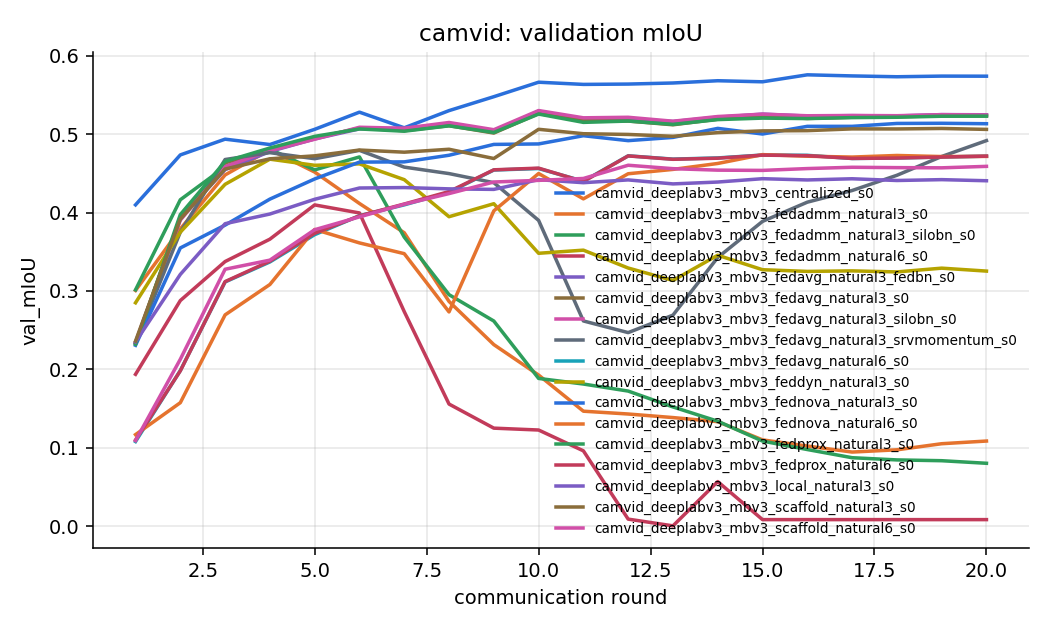

**pets_mIoU_vs_comm.png**

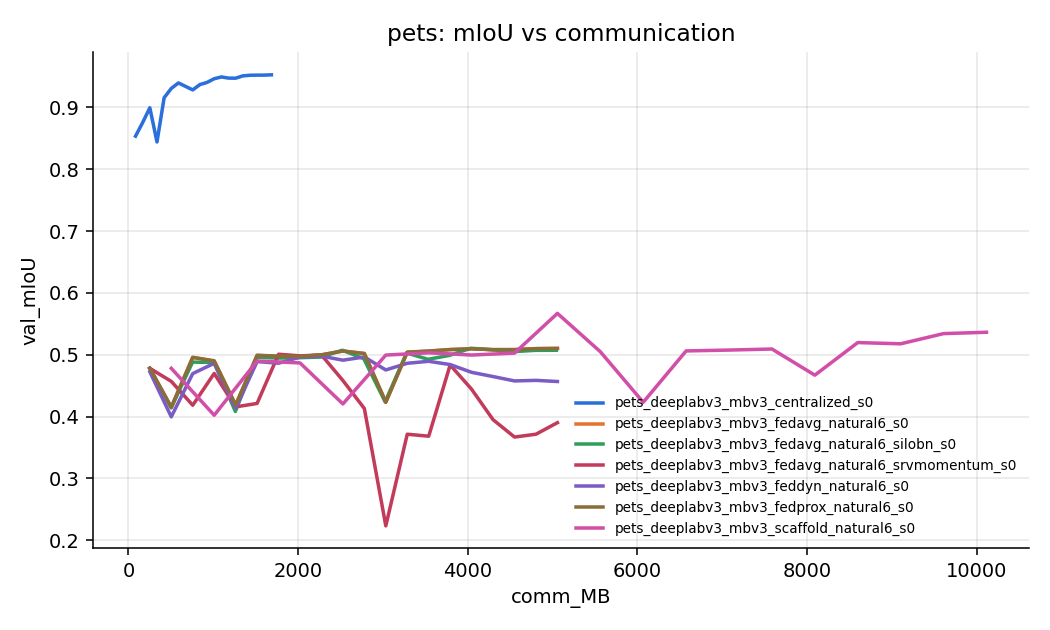

**pets_train_loss.png**

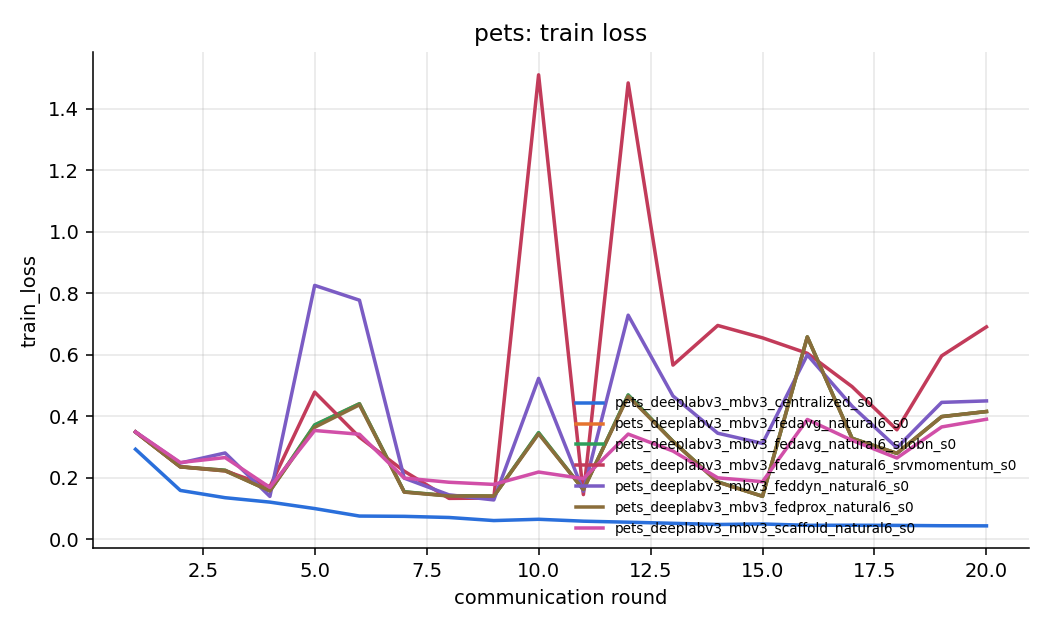

**pets_val_mIoU.png**

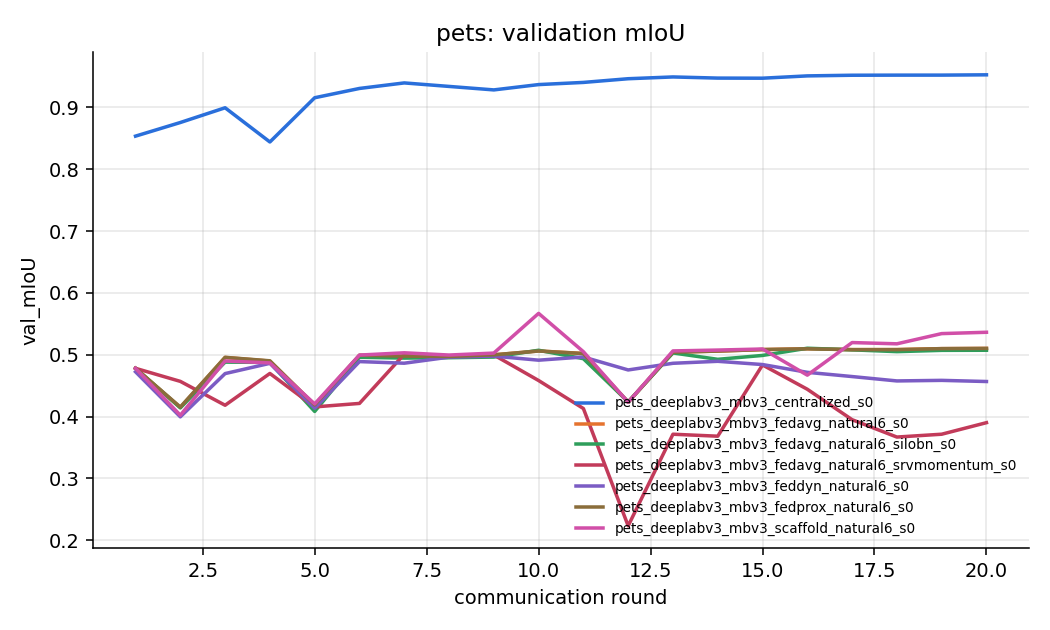

In [ ]:
!python compare.py --runs {OUT_DIR} --out {OUT_DIR}/_summary
for f in sorted(os.listdir(f'{OUT_DIR}/_summary')):
    if f.endswith('.png'):
        display(Markdown(f'**{f}**')); display(Image(f'{OUT_DIR}/_summary/{f}', width=650))

### camvid: best run `camvid_deeplabv3_mbv3_centralized_s0`

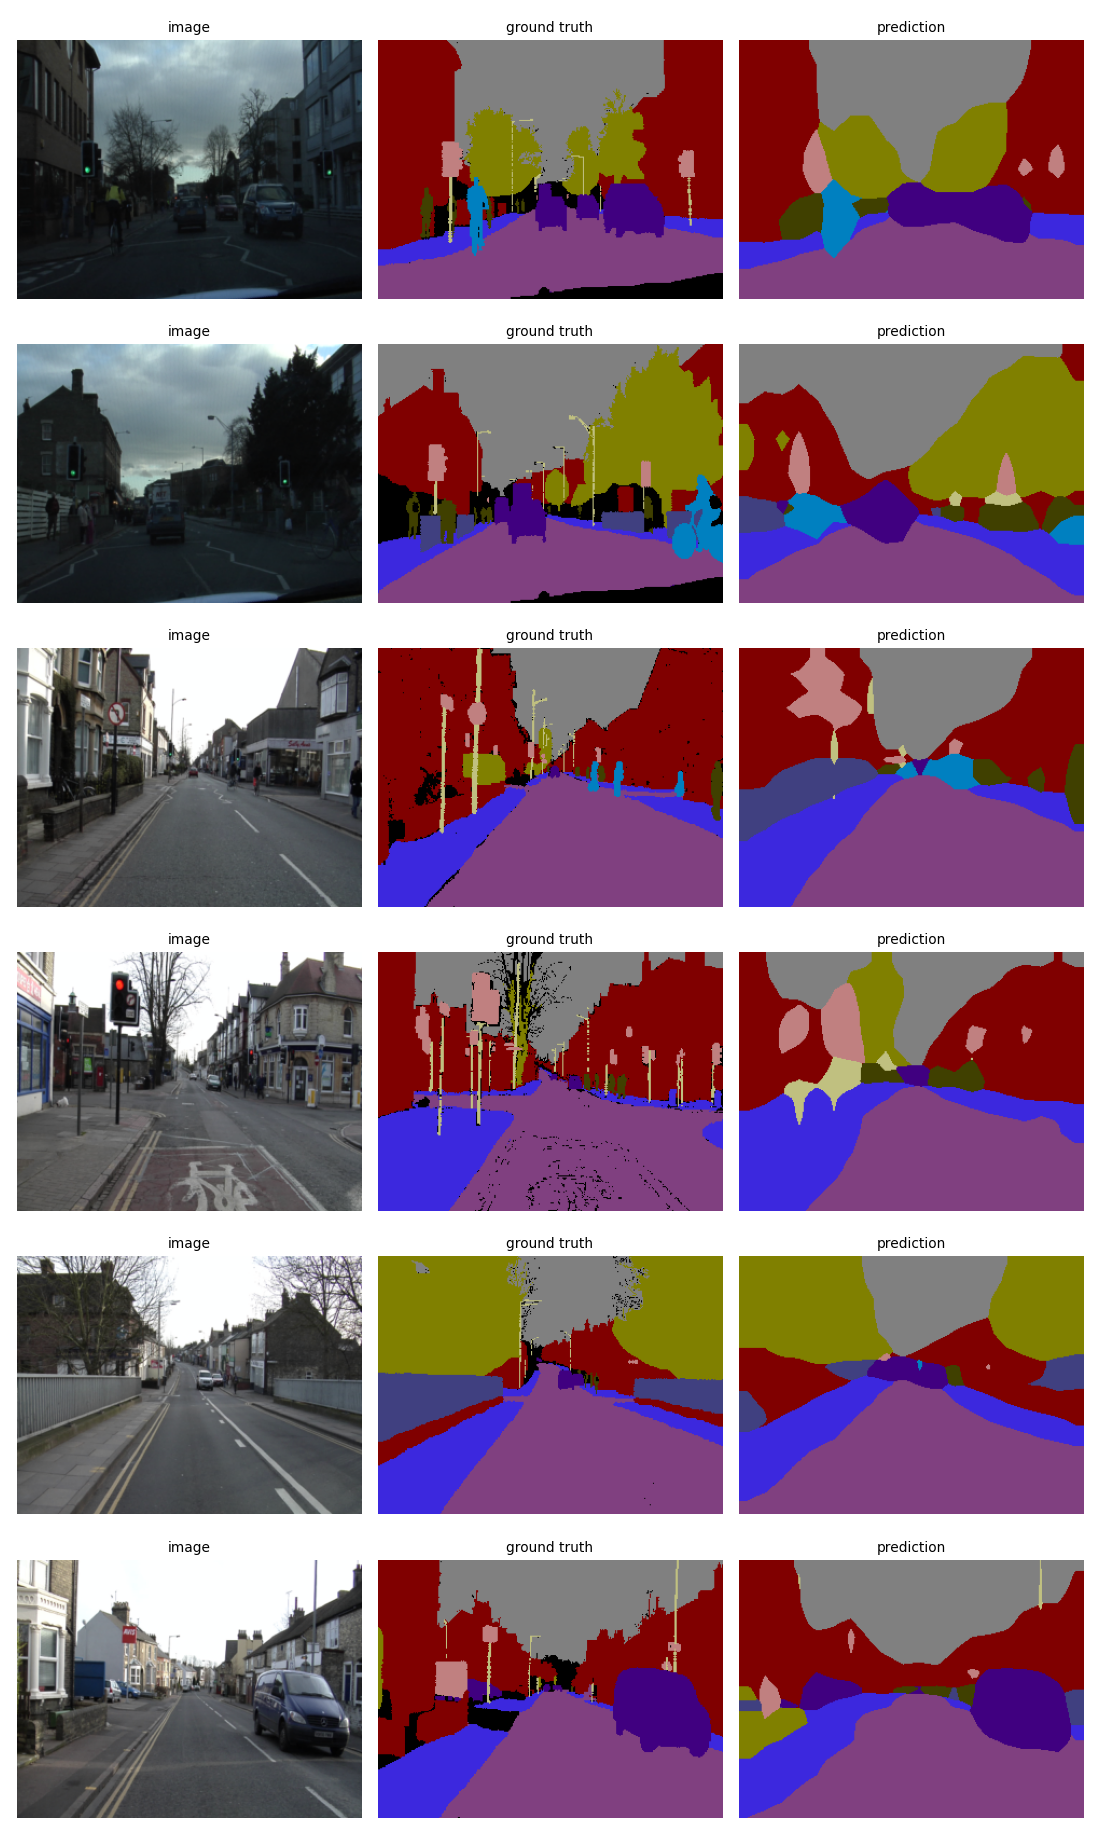

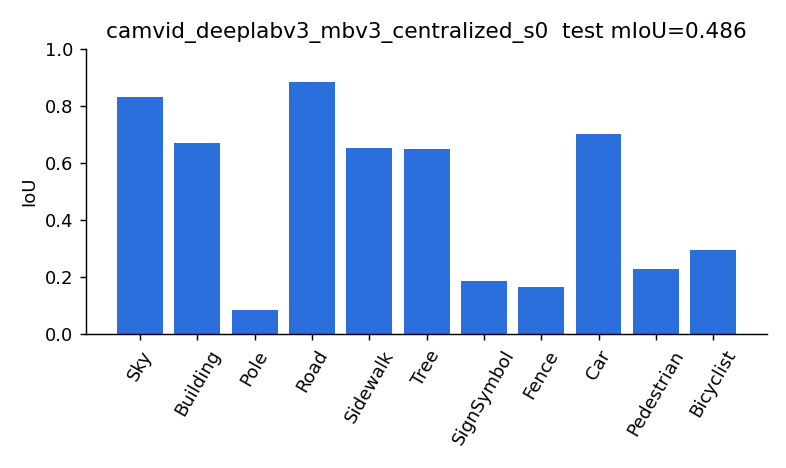

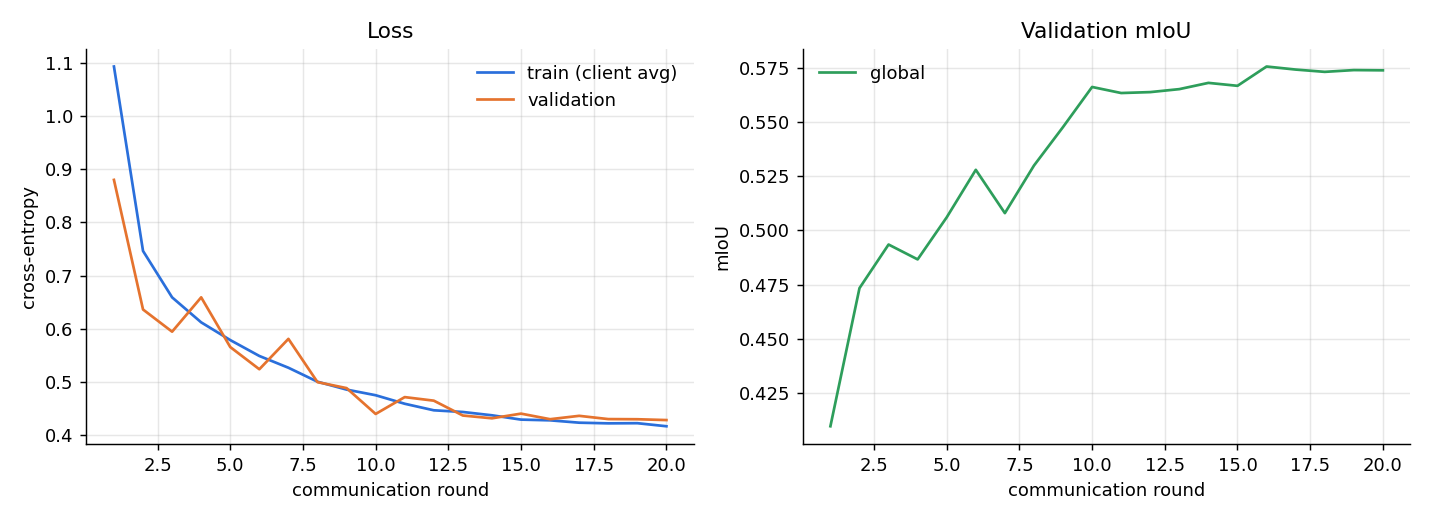

### pets: best run `pets_deeplabv3_mbv3_centralized_s0`

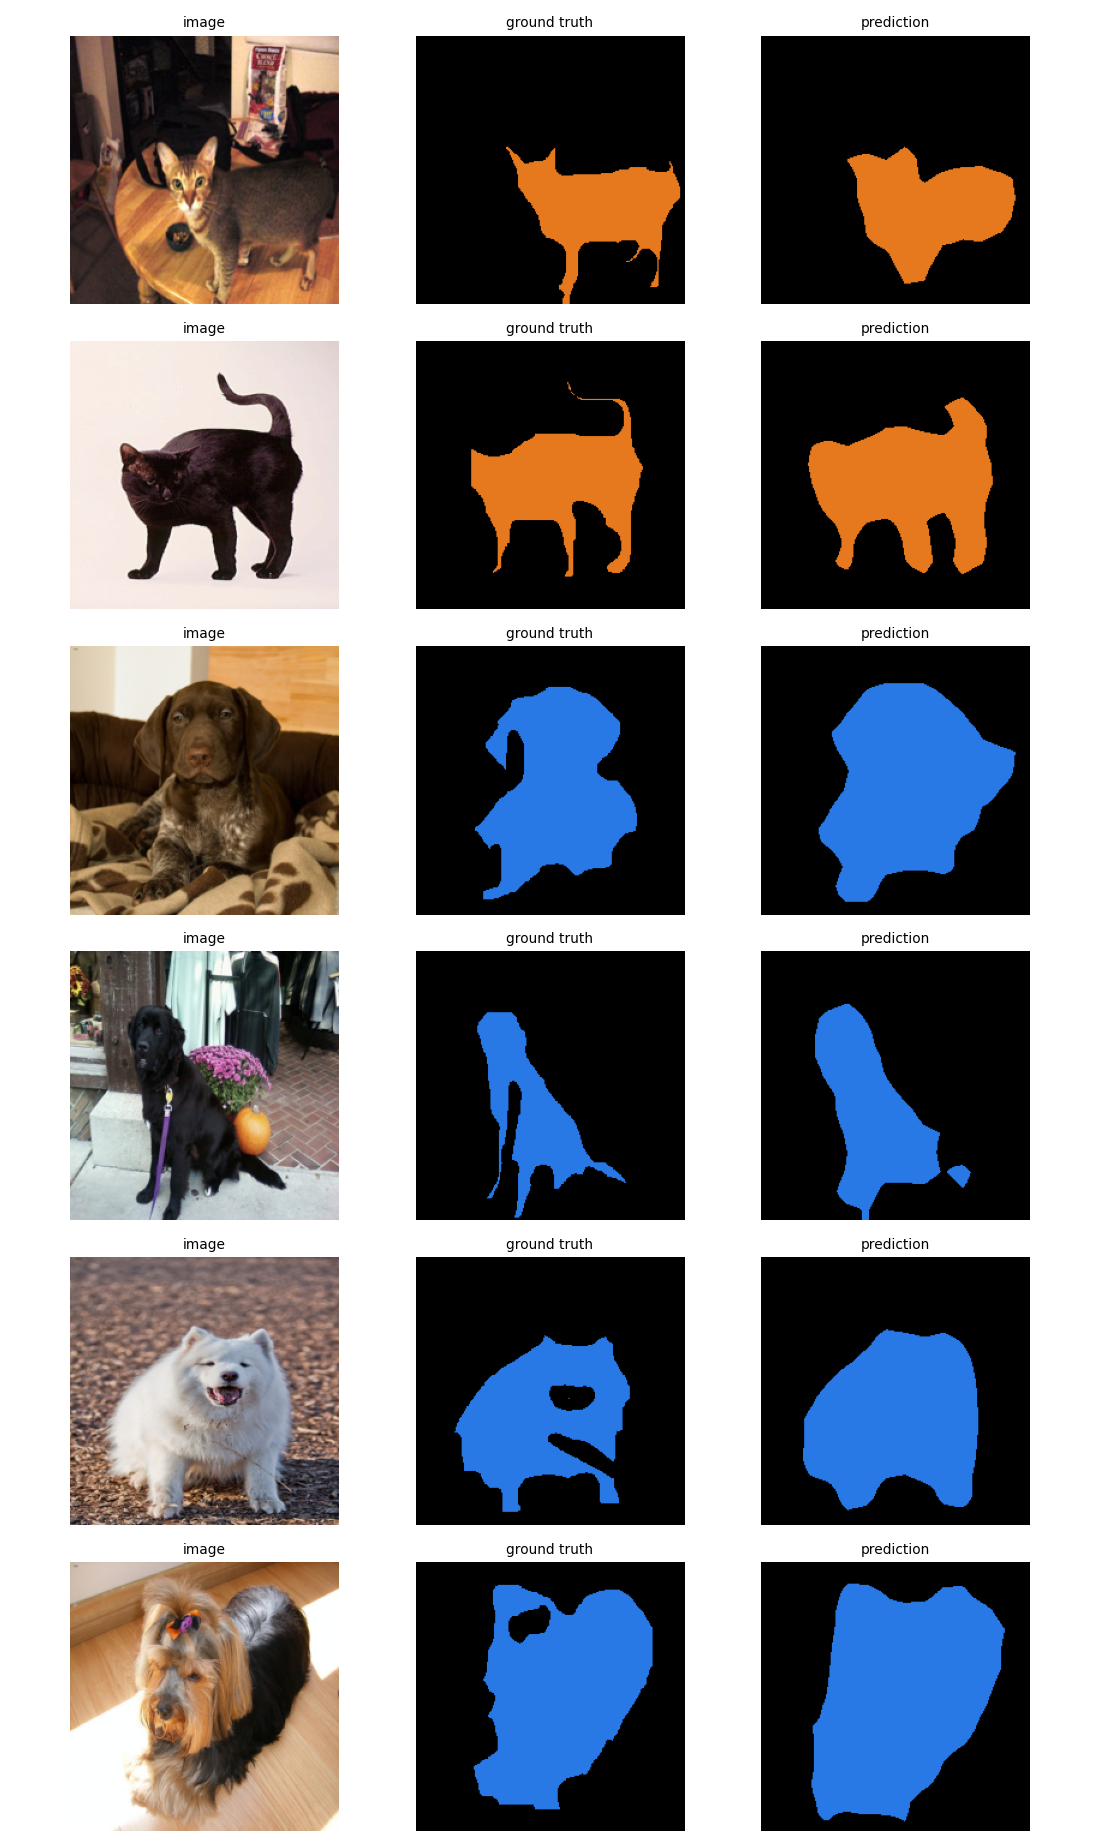

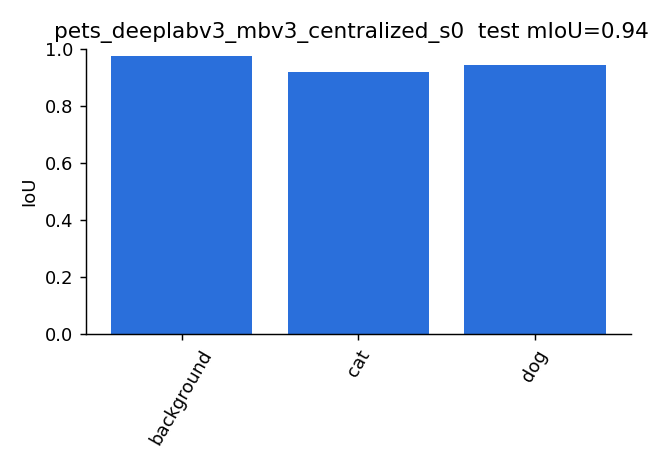

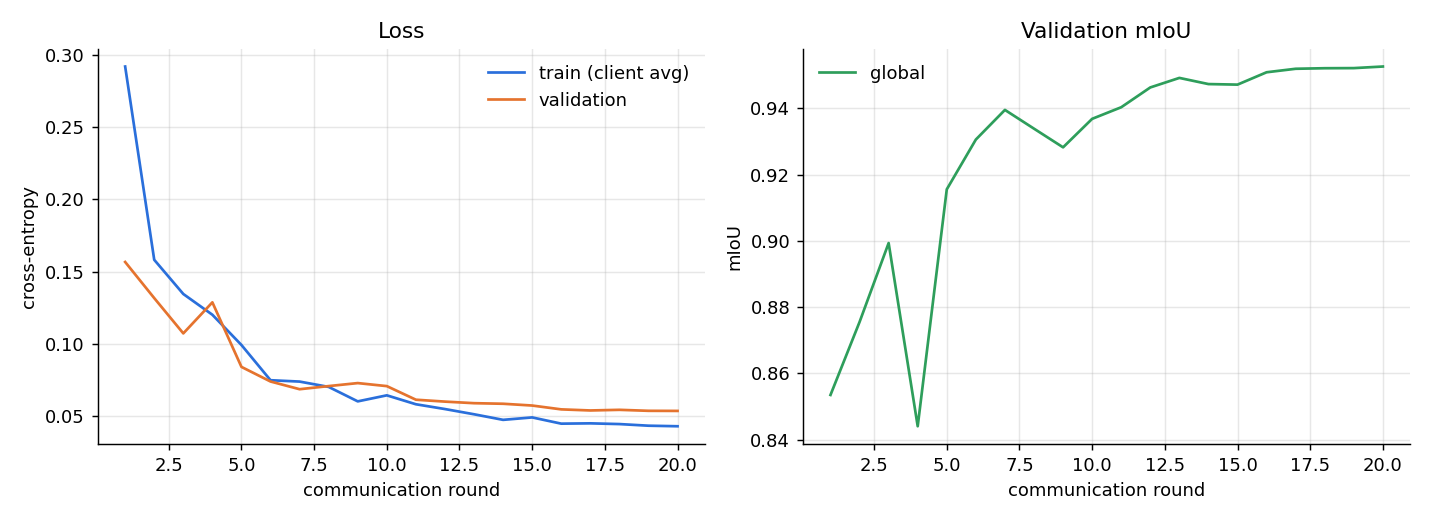

In [ ]:
# qualitative results + per-class IoU of the best run on each dataset
for ds in df.dataset.unique():
    best = df[df.dataset == ds].iloc[0]['run']
    display(Markdown(f'### {ds}: best run `{best}`'))
    for f in ['predictions.png', 'per_class_iou.png', 'curves.png']:
        p = os.path.join(OUT_DIR, best, f)
        if os.path.exists(p):
            display(Image(p, width=700))

## 5. Export

In [ ]:
# zip everything except model checkpoints (they are large) and download it
!cd {OUT_DIR}/.. && zip -q -r /content/fedseg_results.zip $(basename {OUT_DIR}) -x '*.pt'
from google.colab import files
files.download('/content/fedseg_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>